# Exploration du dataset complet (2014 → 2026)

Données : `data/processed_data/*.csv`, chargées avec `dataset_create.charger()` (voir `data/processed_data/README.md`).

In [2]:
import sys; sys.path.append("..")  # pour importer dataset_create depuis notebooks/
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

from dataset_create import charger

df = charger(imputer = True)

AXES = ["Champs-Elysees", "Convention", "Saints-Peres"]
COULEURS = {"Champs-Elysees": "#2a78d6", "Convention": "#eb6834", "Saints-Peres": "#1baf7a"}
print(df.shape)
df.head()

(337464, 22)


,axe,arc_id,debit,occupation,etat_trafic,datetime,impute_debit,impute_occupation,temperature_2m,relative_humidity_2m,precipitation,snowfall,cloud_cover,wind_speed_10m,weather_code,ferie,pont,vacances,paris_respire,evenement,confinement,chantier
0,Champs-Elysees,4264,4.0,0.00000,Fluide,2014-01-01 01:00:00+01:00,False,False,5.9,91,0.0,0.0,10,17.0,0,True,False,Vacances de Noël,False,False,False,0
1,Champs-Elysees,4264,21.0,0.10445,Fluide,2014-01-01 02:00:00+01:00,False,False,5.5,93,0.0,0.0,5,16.3,0,True,False,Vacances de Noël,False,False,False,0
2,Champs-Elysees,4264,417.0,6.12667,Fluide,2014-01-01 03:00:00+01:00,False,False,5.2,93,0.0,0.0,8,17.1,0,True,False,Vacances de Noël,False,False,False,0
3,Champs-Elysees,4264,1089.0,14.39890,Fluide,2014-01-01 04:00:00+01:00,False,False,5.0,94,0.0,0.0,3,16.8,0,True,False,Vacances de Noël,False,False,False,0
4,Champs-Elysees,4264,943.0,10.35220,Fluide,2014-01-01 05:00:00+01:00,False,False,4.9,94,0.0,0.0,13,16.4,0,True,False,Vacances de Noël,False,False,False,0


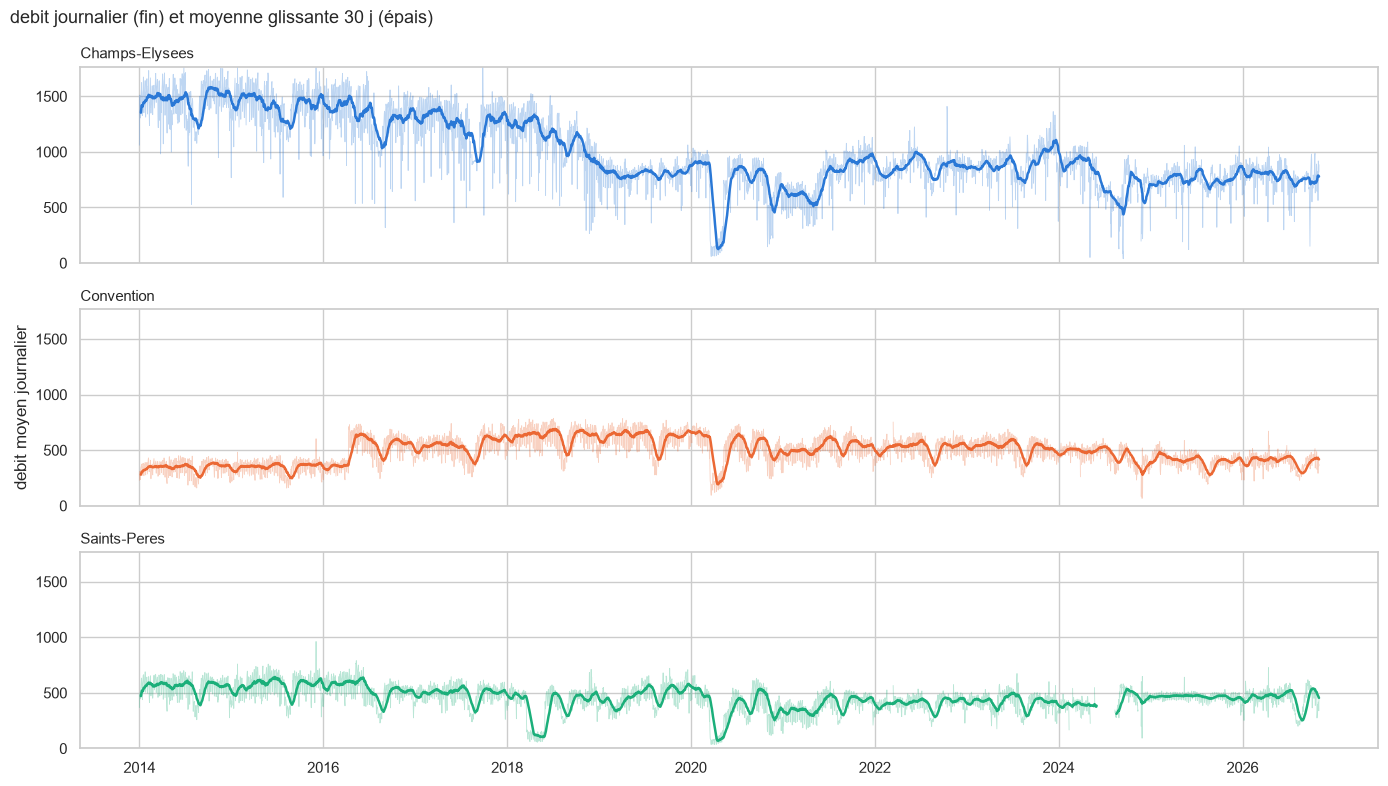

In [4]:
VARIABLE = "debit"

jour = df.groupby(["axe", df["datetime"].dt.date])[VARIABLE].mean().unstack("axe")
jour.index = pd.to_datetime(jour.index)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, axe in zip(axes, AXES):
    ax.plot(jour.index, jour[axe], color=COULEURS[axe], alpha=0.3, linewidth=0.6)
    ax.plot(jour.index, jour[axe].rolling(30, min_periods=7).mean(), color=COULEURS[axe], linewidth=1.8)
    ax.set_title(axe, loc="left", fontsize=11)
axes[0].set_ylim(0, jour.quantile(0.999).max())  # coupe les pics aberrants
axes[1].set_ylabel(f"{VARIABLE} moyen journalier")
fig.suptitle(f"{VARIABLE} journalier (fin) et moyenne glissante 30 j (épais)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

## Tester un LightGBM en 3 lignes

`split(df, t0)` rejoue le challenge : train = tout avant `t0`, test = les 120 h (sam → mer) qui démarrent 1 j après, vraies valeurs seulement.
Options : `cible="occupation"`, `gap="6D"`, `features=[...]` (défaut : `FEATURES`). `ORIGINES` = tous les vendredis nov. 2024 → oct. 2026.

In [5]:
import lightgbm as lgb
from dataset_create import split, ORIGINES, FEATURES

rmse = lambda y, p, axe: ((y - p) ** 2).groupby(axe, observed=True).mean() ** .5  # RMSE par axe

# 1) Une seule date : la semaine du 11/11/2025 (les 3 axes ont des données)
X_train, X_test, y_train, y_test = split(df, "2025-11-07")
model = lgb.LGBMRegressor(verbose=-1).fit(X_train, y_train)
print(pd.DataFrame({"lgbm": rmse(y_test, model.predict(X_test), X_test.axe),
                    "naif_lag7j": rmse(y_test, X_test.lag_7j, X_test.axe)}).round(1))

                 lgbm  naif_lag7j
axe                              
Champs-Elysees  125.4       266.5
Convention       59.2        90.2
Saints-Peres     43.3        72.3


Un seul essai est très bruité (RMSE de 37 à 220 selon la semaine) : on compare les modèles sur **plusieurs origines** (backtest). `ORIGINES[::4]` = 1 vendredi sur 4, pour aller vite.

                 lgbm  naif_lag7j
axe                              
Champs-Elysees  128.3       168.4
Convention       72.8        83.4
Saints-Peres     69.4        80.9 

Moyenne des 3 axes :
 lgbm           90.2
naif_lag7j    110.9
dtype: float64


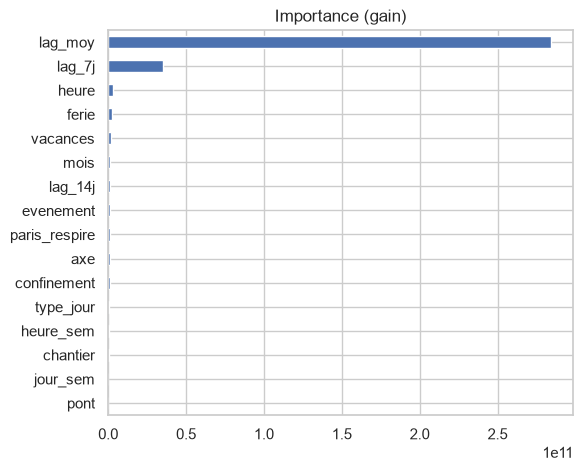

In [6]:
# 2) Backtest : même chose sur plusieurs dates, puis moyenne
res = []
for t0 in ORIGINES[::4]:
    X_train, X_test, y_train, y_test = split(df, t0)  # essaie features=[...] ou cible="occupation"
    if X_test.empty:  # aucun axe avec assez de vraies valeurs cette semaine-là
        continue
    model = lgb.LGBMRegressor(verbose=-1).fit(X_train, y_train)
    res.append(pd.DataFrame({"lgbm": rmse(y_test, model.predict(X_test), X_test.axe),
                             "naif_lag7j": rmse(y_test, X_test.lag_7j, X_test.axe)}).assign(t0=t0))
res = pd.concat(res)

par_axe = res.groupby(level=0).mean(numeric_only=True)
print(par_axe.round(1), "\n\nMoyenne des 3 axes :\n", par_axe.mean().round(1))

# importance des features (dernier modèle)
pd.Series(model.booster_.feature_importance("gain"), X_train.columns).sort_values().plot.barh(figsize=(6, 5), title="Importance (gain)")
plt.show()

## Exemple pour l'équipe : un XGBoost de A à Z

1. **Charger les données** avec `charger()` :
   - `charger(imputer=False)` : les heures sans mesure fiable restent en **NaN** (XGBoost sait gérer les NaN dans les features).
   - `charger(imputer=True)` : les trous sont **comblés** (débit via les rues voisines, occupation via son profil passé). Les colonnes `impute_debit` / `impute_occupation` disent quelles lignes ont été inventées.
2. **Couper train / test** avec `split(df, t0, cible=...)` : on se place au vendredi `t0` (= dernière donnée connue) et on prédit les 120 h du samedi au mercredi, comme le jour J. Le test ne contient **que de vraies valeurs** (jamais d'imputées).
3. **Entraîner, prédire, comparer** au naïf « même heure la semaine dernière » (`lag_7j`).

À tester : `cible="occupation"`, une autre date `t0` (voir `ORIGINES`), les hyperparamètres de XGBoost, et les features :
- `features=None` (défaut) : notre sélection `FEATURES` ;
- `features="toutes"` : toutes les features utilisables `TOUTES` (+ météo, `chantier`, `lag_21j`/`lag_28j`, testées puis écartées) ;
- `features=[...]` : sa propre liste de colonnes (prises dans `TOUTES`).

In [ ]:
import xgboost as xgb
from dataset_create import charger, split, FEATURES, TOUTES

# 1) Données : imputer=True -> trous comblés ; imputer=False -> trous en NaN
df = charger(imputer=True)
print(df[["axe", "datetime", "debit", "occupation", "impute_debit", "impute_occupation"]].tail(3))
print("Sélection par défaut :", FEATURES)
print("Features en plus avec features='toutes' :", [f for f in TOUTES if f not in FEATURES])

# 2) Train / test : dernière donnée connue = vendredi 07/11/2025 -> on prédit sam 08 -> mer 12/11 (11/11 férié inclus)
CIBLE = "debit"  # ou "occupation"
X_train, X_test, y_train, y_test = split(df, "2025-11-07", cible=CIBLE)  # features="toutes" ou features=[...]

# 3) Modèle (enable_categorical : `axe` et `vacances` sont des catégories)
model = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, enable_categorical=True, tree_method="hist")
model.fit(X_train, y_train)
pred = model.predict(X_test)

# 4) Score : RMSE par arc, comparé au naïf "même heure la semaine dernière"
rmse = lambda p: ((y_test - p) ** 2).groupby(X_test.axe, observed=True).mean() ** .5
print(pd.DataFrame({"xgboost": rmse(pred), "naif_lag7j": rmse(X_test.lag_7j)}).round(1))

# 5) Visualiser la semaine prédite vs la réalité
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, axe in zip(axes, AXES):
    m = (X_test.axe == axe).values
    ax.plot(y_test.values[m], color=COULEURS[axe], label="réel")
    ax.plot(pred[m], color="black", linestyle="--", label="XGBoost")
    ax.set_title(axe, loc="left", fontsize=11)
axes[0].legend()
axes[-1].set_xlabel("heures depuis samedi 00h")
fig.suptitle(f"{CIBLE} : semaine du 08 au 12/11/2025", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()